In [1]:
from google.colab import drive
drive.mount('/content/drive')

import os
BASE = "/content/drive/MyDrive/solar-underperformance-detector"
print(os.listdir(BASE))
print(os.listdir(f"{BASE}/data"))

Mounted at /content/drive
['requirements.txt', 'run_app.bat', 'models', 'notebooks', 'data', 'app']
['Plant_1_Generation_Data.csv', 'Plant_1_Weather_Sensor_Data.csv']


In [2]:
import sqlite3
import pandas as pd

gen = pd.read_csv(f"{BASE}/data/Plant_1_Generation_Data.csv")
weather = pd.read_csv(f"{BASE}/data/Plant_1_Weather_Sensor_Data.csv")

gen["DATE_TIME"] = pd.to_datetime(gen["DATE_TIME"], format="%d-%m-%Y %H:%M")
weather["DATE_TIME"] = pd.to_datetime(weather["DATE_TIME"])
weather = weather.drop(columns=["PLANT_ID", "SOURCE_KEY"])

DB_PATH = f"{BASE}/data/solar.db"
con = sqlite3.connect(DB_PATH)
gen.to_sql("generation", con, if_exists="replace", index=False)
weather.to_sql("weather", con, if_exists="replace", index=False)
con.execute("CREATE INDEX IF NOT EXISTS idx_gen_time ON generation(DATE_TIME)")
con.execute("CREATE INDEX IF NOT EXISTS idx_gen_inv ON generation(SOURCE_KEY)")
con.commit()

print("Rows in generation:", pd.read_sql("SELECT COUNT(*) AS n FROM generation", con).iloc[0, 0])
print("Rows in weather:", pd.read_sql("SELECT COUNT(*) AS n FROM weather", con).iloc[0, 0])

Rows in generation: 68778
Rows in weather: 3182


In [3]:
query = """
SELECT SOURCE_KEY,
       COUNT(*)                 AS n_readings,
       ROUND(AVG(AC_POWER), 1)  AS avg_ac_kw,
       ROUND(MAX(AC_POWER), 1)  AS max_ac_kw
FROM generation
GROUP BY SOURCE_KEY
ORDER BY avg_ac_kw
"""
inverter_summary = pd.read_sql(query, con)
inverter_summary

,SOURCE_KEY,n_readings,avg_ac_kw,max_ac_kw
0,bvBOhCH3iADSZry,3155,276.8,1265.2
1,1BY6WEcLGh8j5v7,3154,281.1,1300.2
2,ih0vzX44oOqAx2f,3130,303.0,1377.3
3,7JYdWkrLSPkdwr4,3133,306.4,1384.9
4,z9Y9gH1T5YWrNuG,3126,306.5,1401.1
5,ZoEaEvLYb1n2sOq,3123,307.0,1395.5
6,sjndEbLyjtCKgGv,3124,307.9,1399.8
7,zBIq5rxdHJRwDNY,3119,307.9,1393.2
8,WRmjgnKYAwPKWDb,3118,308.6,1376.3
9,rGa61gmuvPhdLxV,3124,309.3,1392.8


In [4]:
query = """
SELECT g.DATE_TIME, g.SOURCE_KEY, g.AC_POWER,
       w.IRRADIATION, w.AMBIENT_TEMPERATURE, w.MODULE_TEMPERATURE
FROM generation g
JOIN weather w ON g.DATE_TIME = w.DATE_TIME
WHERE w.IRRADIATION > 0.05
"""
df = pd.read_sql(query, con, parse_dates=["DATE_TIME"])
df = df.sort_values(["SOURCE_KEY", "DATE_TIME"]).reset_index(drop=True)
print(df.shape)
df.head()

(33266, 6)


,DATE_TIME,SOURCE_KEY,AC_POWER,IRRADIATION,AMBIENT_TEMPERATURE,MODULE_TEMPERATURE
0,2020-05-15 06:45:00,1BY6WEcLGh8j5v7,119.275000,0.095394,24.218990,24.442444
1,2020-05-15 07:00:00,1BY6WEcLGh8j5v7,170.014286,0.141940,24.537398,27.185653
2,2020-05-15 07:15:00,1BY6WEcLGh8j5v7,181.937500,0.154713,24.815960,28.888478
3,2020-05-15 07:30:00,1BY6WEcLGh8j5v7,180.585714,0.148799,24.988790,29.605644
4,2020-05-15 07:45:00,1BY6WEcLGh8j5v7,184.062500,0.144793,25.216180,29.547111


In [5]:
# Median output of all inverters at each timestamp
df["PEER_MEDIAN"] = df.groupby("DATE_TIME")["AC_POWER"].transform("median")

# Ignore very low-output moments (dawn/dusk) where ratios are unstable
df = df[df["PEER_MEDIAN"] > 50].copy()
df["PEER_RATIO"] = df["AC_POWER"] / df["PEER_MEDIAN"]

# Smooth over 1 hour (4 readings) within each inverter-day so brief dips aren't flagged
df["DATE"] = df["DATE_TIME"].dt.date
df["RATIO_1H"] = (
    df.groupby(["SOURCE_KEY", "DATE"])["PEER_RATIO"]
      .transform(lambda s: s.rolling(4, min_periods=4).median())
)
df = df.dropna(subset=["RATIO_1H"]).copy()

THRESHOLD = 0.80
df["LABEL"] = (df["RATIO_1H"] < THRESHOLD).astype(int)

print("Rows:", len(df))
print("Overall flagged share:", round(df["LABEL"].mean(), 4))

Rows: 31022
Overall flagged share: 0.0035


                 mean_ratio  pct_flagged
SOURCE_KEY                              
bvBOhCH3iADSZry       0.908        0.020
1BY6WEcLGh8j5v7       0.921        0.022
ih0vzX44oOqAx2f       0.980        0.001
ZoEaEvLYb1n2sOq       0.991        0.000
7JYdWkrLSPkdwr4       0.991        0.000
z9Y9gH1T5YWrNuG       0.992        0.006
zBIq5rxdHJRwDNY       0.994        0.002
YxYtjZvoooNbGkE       0.996        0.000
WRmjgnKYAwPKWDb       0.996        0.000
sjndEbLyjtCKgGv       0.997        0.004
wCURE6d3bPkepu2       1.001        0.005
rGa61gmuvPhdLxV       1.002        0.004
pkci93gMrogZuBj       1.004        0.002
zVJPv84UY57bAof       1.006        0.003
iCRJl6heRkivqQ3       1.009        0.000
ZnxXDlPa8U1GXgE       1.010        0.000
uHbuxQJl8lW7ozc       1.012        0.002
VHMLBKoKgIrUVDU       1.015        0.000
3PZuoBAID5Wc2HD       1.015        0.000
McdE0feGgRqW7Ca       1.016        0.006
1IF53ai7Xc0U56Y       1.017        0.000
adLQvlD726eNBSB       1.030        0.000


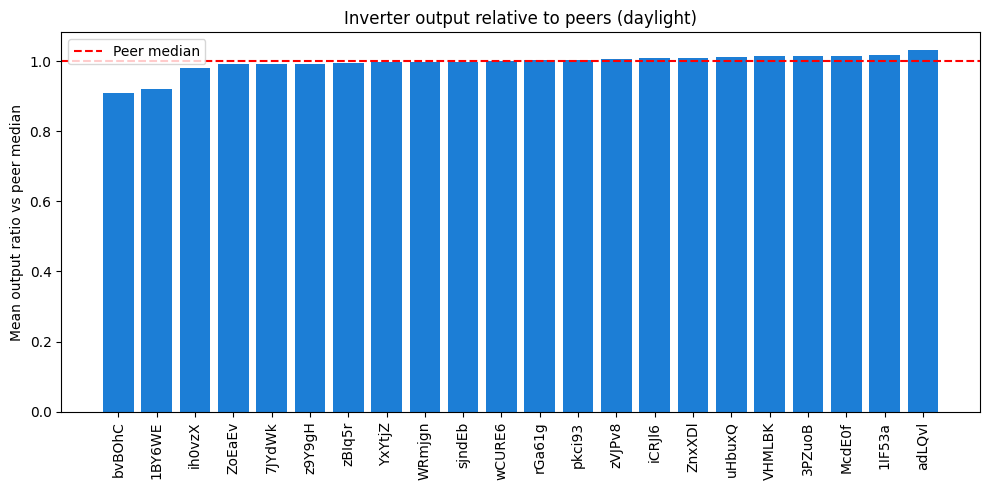

In [6]:
import matplotlib.pyplot as plt

summary = (df.groupby("SOURCE_KEY")
             .agg(mean_ratio=("PEER_RATIO", "mean"),
                  pct_flagged=("LABEL", "mean"))
             .sort_values("mean_ratio"))
print(summary.round(3))

os.makedirs(f"{BASE}/images", exist_ok=True)
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(range(len(summary)), summary["mean_ratio"], color="#1c7ed6")
ax.axhline(1.0, color="red", linestyle="--", label="Peer median")
ax.set_xticks(range(len(summary)))
ax.set_xticklabels([k[:6] for k in summary.index], rotation=90)
ax.set_ylabel("Mean output ratio vs peer median")
ax.set_title("Inverter output relative to peers (daylight)")
ax.legend()
plt.tight_layout()
plt.savefig(f"{BASE}/images/peer_ratio_by_inverter.png", dpi=150)
plt.show()

In [7]:
for t in [0.70, 0.75, 0.80, 0.85, 0.90]:
    print(f"threshold {t:.2f} -> flagged share {(df['RATIO_1H'] < t).mean():.4f}")

threshold 0.70 -> flagged share 0.0030
threshold 0.75 -> flagged share 0.0032
threshold 0.80 -> flagged share 0.0035
threshold 0.85 -> flagged share 0.0065
threshold 0.90 -> flagged share 0.0245


In [8]:
df["HOUR"] = df["DATE_TIME"].dt.hour + df["DATE_TIME"].dt.minute / 60
feature_cols = ["IRRADIATION", "AMBIENT_TEMPERATURE", "MODULE_TEMPERATURE", "HOUR"]

print("Total rows:", len(df))
print("Flagged rows (LABEL=1):", int(df["LABEL"].sum()))

# Healthy pool: not flagged, and not from the two chronically weak inverters
weak_inverters = summary.index[summary["mean_ratio"] < 0.95].tolist()
print("Chronically weak inverters:", weak_inverters)

healthy = df[(df["LABEL"] == 0) & (~df["SOURCE_KEY"].isin(weak_inverters))].copy()
healthy = healthy.sort_values("DATE_TIME").reset_index(drop=True)

cutoff = healthy["DATE_TIME"].iloc[int(len(healthy) * 0.8)]
train = healthy[healthy["DATE_TIME"] <= cutoff]
test = healthy[healthy["DATE_TIME"] > cutoff]

print("Train:", len(train), train["DATE_TIME"].min().date(), "to", train["DATE_TIME"].max().date())
print("Test: ", len(test), test["DATE_TIME"].min().date(), "to", test["DATE_TIME"].max().date())

Total rows: 31022
Flagged rows (LABEL=1): 109
Chronically weak inverters: ['bvBOhCH3iADSZry', '1BY6WEcLGh8j5v7']
Train: 22533 2020-05-15 to 2020-06-11
Test:  5617 2020-06-11 to 2020-06-17


In [9]:
import numpy as np
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from xgboost import XGBRegressor
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear (irradiation only)": (LinearRegression(), ["IRRADIATION"]),
    "Linear (4 features)": (LinearRegression(), feature_cols),
    "Random Forest": (RandomForestRegressor(n_estimators=200, max_depth=12,
                      min_samples_leaf=5, n_jobs=-1, random_state=42), feature_cols),
    "XGBoost": (XGBRegressor(n_estimators=300, max_depth=4, learning_rate=0.05,
                subsample=0.8, random_state=42), feature_cols),
}

tscv = TimeSeriesSplit(n_splits=5)
rows = []
for name, (model, cols) in models.items():
    cv_mae = -cross_val_score(model, train[cols], train["AC_POWER"],
                              cv=tscv, scoring="neg_mean_absolute_error").mean()
    model.fit(train[cols], train["AC_POWER"])
    pred = np.clip(model.predict(test[cols]), 0, None)
    rows.append({
        "Model": name,
        "CV MAE (kW)": cv_mae,
        "Test MAE (kW)": mean_absolute_error(test["AC_POWER"], pred),
        "Test RMSE (kW)": np.sqrt(mean_squared_error(test["AC_POWER"], pred)),
        "Test R2": r2_score(test["AC_POWER"], pred),
    })

results = pd.DataFrame(rows).round(3)
results

,Model,CV MAE (kW),Test MAE (kW),Test RMSE (kW),Test R2
0,Linear (irradiation only),46.627,43.070,57.073,0.965
1,Linear (4 features),47.072,43.467,57.272,0.964
2,Random Forest,44.553,30.610,47.757,0.975
3,XGBoost,41.803,27.311,43.892,0.979


In [10]:
import joblib
from sklearn.metrics import (average_precision_score, precision_score,
                             recall_score, f1_score)

os.makedirs(f"{BASE}/models", exist_ok=True)
joblib.dump(models["XGBoost"][0], f"{BASE}/models/expected_power_xgb.joblib")

test_all = (df[df["DATE_TIME"] > cutoff]
            .sort_values(["SOURCE_KEY", "DATE_TIME"]).copy())

def detection_scores(model, cols, data):
    d = data.copy()
    d["EXPECTED"] = np.clip(model.predict(d[cols]), 1, None)
    d["MODEL_RATIO"] = d["AC_POWER"] / d["EXPECTED"]
    # df was already trimmed when labels were built, so min_periods=1 here
    d["MODEL_RATIO_1H"] = (d.groupby(["SOURCE_KEY", "DATE"])["MODEL_RATIO"]
                             .transform(lambda s: s.rolling(4, min_periods=1).median()))
    return d

print("Test rows:", len(test_all), "| flagged (positives):", int(test_all["LABEL"].sum()))
print("Random-guess PR-AUC baseline:", round(test_all["LABEL"].mean(), 4))

Test rows: 6182 | flagged (positives): 33
Random-guess PR-AUC baseline: 0.0053


In [11]:
rows = []
for name in ["Linear (irradiation only)", "XGBoost"]:
    m, cols = models[name]
    d = detection_scores(m, cols, test_all)
    y = d["LABEL"]
    ap = average_precision_score(y, 1 - d["MODEL_RATIO_1H"])
    for thr in [0.80, 0.85]:
        pred = (d["MODEL_RATIO_1H"] < thr).astype(int)
        rows.append({
            "Expected-power model": name, "Alert threshold": thr, "PR-AUC": round(ap, 3),
            "Precision": round(precision_score(y, pred, zero_division=0), 3),
            "Recall": round(recall_score(y, pred, zero_division=0), 3),
            "F1": round(f1_score(y, pred, zero_division=0), 3),
            "Alerts": int(pred.sum()),
        })
pd.DataFrame(rows)

,Expected-power model,Alert threshold,PR-AUC,Precision,Recall,F1,Alerts
0,Linear (irradiation only),0.80,1.0,0.508,1.0,0.673,65
1,Linear (irradiation only),0.85,1.0,0.133,1.0,0.234,249
2,XGBoost,0.80,1.0,1.000,1.0,1.000,33
3,XGBoost,0.85,1.0,0.805,1.0,0.892,41


In [12]:
d_xgb = detection_scores(*models["XGBoost"], test_all)
print(d_xgb.groupby("SOURCE_KEY")["MODEL_RATIO"].mean().sort_values().round(3))

SOURCE_KEY
bvBOhCH3iADSZry    0.888
1BY6WEcLGh8j5v7    0.898
ih0vzX44oOqAx2f    0.990
YxYtjZvoooNbGkE    1.000
ZoEaEvLYb1n2sOq    1.000
zBIq5rxdHJRwDNY    1.001
7JYdWkrLSPkdwr4    1.005
z9Y9gH1T5YWrNuG    1.006
WRmjgnKYAwPKWDb    1.010
pkci93gMrogZuBj    1.012
sjndEbLyjtCKgGv    1.014
zVJPv84UY57bAof    1.014
rGa61gmuvPhdLxV    1.014
wCURE6d3bPkepu2    1.016
ZnxXDlPa8U1GXgE    1.019
iCRJl6heRkivqQ3    1.019
uHbuxQJl8lW7ozc    1.020
3PZuoBAID5Wc2HD    1.025
VHMLBKoKgIrUVDU    1.031
McdE0feGgRqW7Ca    1.032
1IF53ai7Xc0U56Y    1.033
adLQvlD726eNBSB    1.046
Name: MODEL_RATIO, dtype: float64


In [13]:
d = detection_scores(*models["XGBoost"], test_all)
print("Correlation, model ratio vs peer ratio:", round(d["MODEL_RATIO_1H"].corr(d["RATIO_1H"]), 4))
print("Mean abs difference:", round((d["MODEL_RATIO_1H"] - d["RATIO_1H"]).abs().mean(), 4))
print("\nPositives by inverter (test period):")
print(d[d["LABEL"] == 1].groupby("SOURCE_KEY").size().sort_values(ascending=False))

Correlation, model ratio vs peer ratio: 0.9444
Mean abs difference: 0.0216

Positives by inverter (test period):
SOURCE_KEY
1BY6WEcLGh8j5v7    15
bvBOhCH3iADSZry    15
zBIq5rxdHJRwDNY     3
dtype: int64


In [14]:
rng = np.random.default_rng(42)
m, cols = models["XGBoost"]

# Healthy test data only: no weak inverters, no flagged rows
healthy_test = (test_all[(test_all["LABEL"] == 0) & (~test_all["SOURCE_KEY"].isin(weak_inverters))]
                .sort_values(["SOURCE_KEY", "DATE_TIME"]).reset_index(drop=True))
healthy_test["EXPECTED"] = np.clip(m.predict(healthy_test[cols]), 1, None)

def rolling_ratio(frame, power_col):
    r = frame[power_col] / frame["EXPECTED"]
    return (r.groupby([frame["SOURCE_KEY"], frame["DATE"]])
              .transform(lambda s: s.rolling(4, min_periods=4).median()))

# False-alarm rate on untouched healthy data
healthy_test["RATIO_1H"] = rolling_ratio(healthy_test, "AC_POWER")

def run_injection(loss, n_events=60, window=8):   # 8 readings = 2-hour fault
    d = healthy_test.copy()
    d["POWER"] = d["AC_POWER"]
    d["INJECTED"] = False
    events = []
    for _ in range(n_events):
        i = int(rng.integers(0, len(d) - window))
        seg = d.iloc[i:i + window]
        if (seg["SOURCE_KEY"].nunique() == 1 and seg["DATE"].nunique() == 1
                and not seg["INJECTED"].any()):
            idx = seg.index
            d.loc[idx, "POWER"] = d.loc[idx, "AC_POWER"] * (1 - loss)
            d.loc[idx, "INJECTED"] = True
            events.append(idx)
    d["RATIO_1H"] = rolling_ratio(d, "POWER")
    return d, events

rows = []
for loss in [0.10, 0.15, 0.20, 0.30, 0.50]:
    d, events = run_injection(loss)
    for thr in [0.80, 0.85]:
        flag = d["RATIO_1H"] < thr
        detected = np.mean([flag.loc[idx].any() for idx in events])
        false_alarm = (healthy_test["RATIO_1H"] < thr).mean()
        rows.append({"Power loss": f"{int(loss*100)}%", "Alert threshold": thr,
                     "Events injected": len(events),
                     "Detected": f"{detected*100:.0f}%",
                     "False-alarm rate (clean rows)": f"{false_alarm*100:.2f}%"})
pd.DataFrame(rows)

,Power loss,Alert threshold,Events injected,Detected,False-alarm rate (clean rows)
0,10%,0.80,41,0%,0.00%
1,10%,0.85,41,2%,0.11%
2,15%,0.80,43,7%,0.00%
3,15%,0.85,43,56%,0.11%
4,20%,0.80,50,52%,0.00%
5,20%,0.85,50,100%,0.11%
6,30%,0.80,46,100%,0.00%
7,30%,0.85,46,100%,0.11%
8,50%,0.80,49,100%,0.00%
9,50%,0.85,49,100%,0.11%


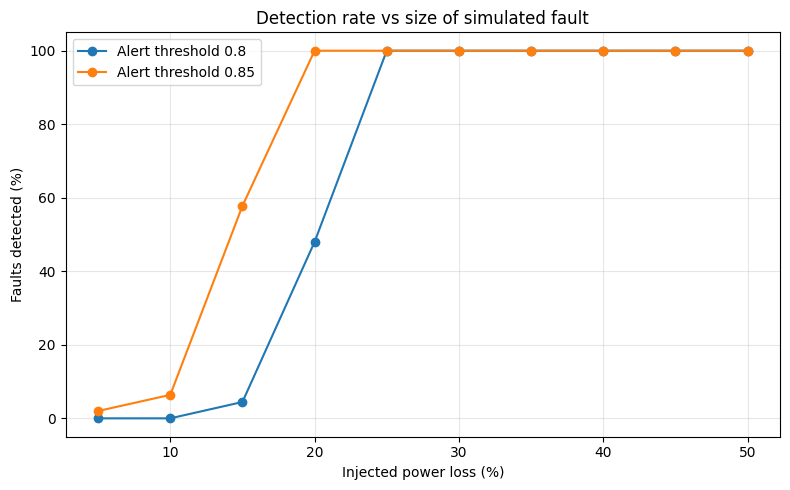

In [15]:
os.makedirs(f"{BASE}/results", exist_ok=True)
inj_table = pd.DataFrame(rows)          # the Cell 14 table
inj_table.to_csv(f"{BASE}/results/fault_injection.csv", index=False)
results.to_csv(f"{BASE}/results/model_comparison.csv", index=False)

losses = np.arange(0.05, 0.55, 0.05)
curve = {0.80: [], 0.85: []}
for loss in losses:
    d_inj, ev = run_injection(loss)
    for thr in curve:
        flag = d_inj["RATIO_1H"] < thr
        curve[thr].append(np.mean([flag.loc[i].any() for i in ev]) * 100)

fig, ax = plt.subplots(figsize=(8, 5))
for thr, vals in curve.items():
    ax.plot(losses * 100, vals, marker="o", label=f"Alert threshold {thr}")
ax.set_xlabel("Injected power loss (%)")
ax.set_ylabel("Faults detected (%)")
ax.set_title("Detection rate vs size of simulated fault")
ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(f"{BASE}/images/detection_curve.png", dpi=150)
plt.show()

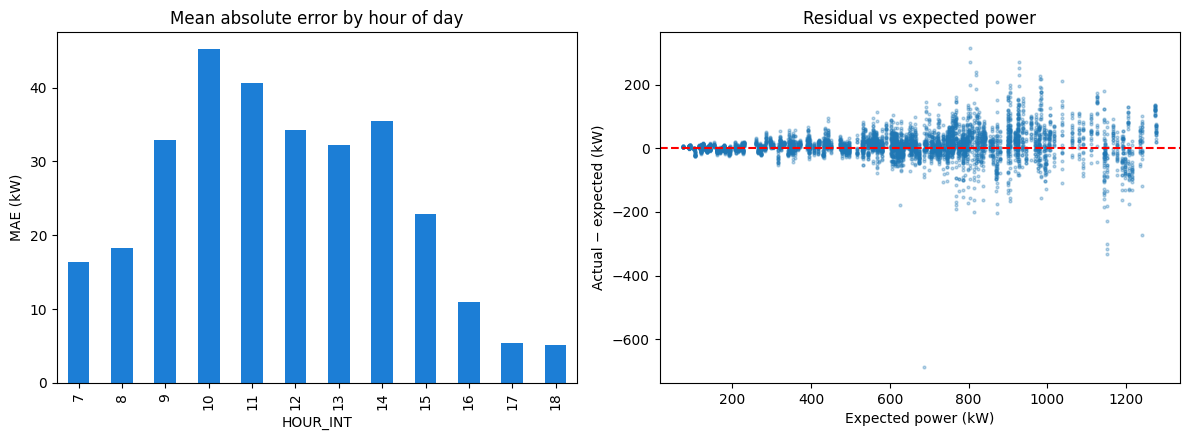

In [16]:
healthy_test["RESID"] = healthy_test["AC_POWER"] - healthy_test["EXPECTED"]
healthy_test["HOUR_INT"] = healthy_test["DATE_TIME"].dt.hour

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
healthy_test.groupby("HOUR_INT")["RESID"].apply(lambda s: s.abs().mean()).plot.bar(ax=axes[0], color="#1c7ed6")
axes[0].set_title("Mean absolute error by hour of day")
axes[0].set_ylabel("MAE (kW)")

axes[1].scatter(healthy_test["EXPECTED"], healthy_test["RESID"], s=4, alpha=0.3)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("Residual vs expected power")
axes[1].set_xlabel("Expected power (kW)"); axes[1].set_ylabel("Actual − expected (kW)")
plt.tight_layout()
plt.savefig(f"{BASE}/images/residuals.png", dpi=150)
plt.show()

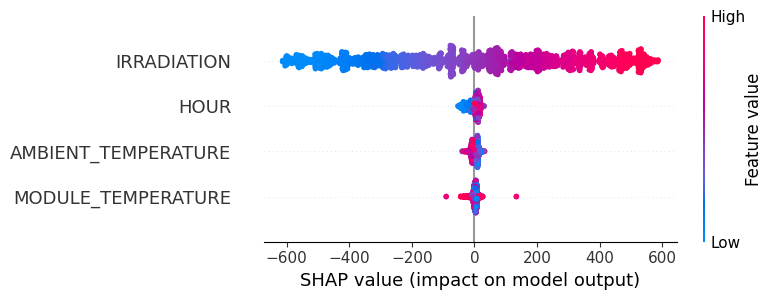

In [17]:
!pip -q install shap
import shap

xgb_model = models["XGBoost"][0]
sample = train[feature_cols].sample(2000, random_state=42)
shap_values = shap.TreeExplainer(xgb_model).shap_values(sample)

shap.summary_plot(shap_values, sample, show=False)
plt.tight_layout()
plt.savefig(f"{BASE}/images/shap_summary.png", dpi=150, bbox_inches="tight")
plt.show()

In [18]:
import json, xgboost
print("xgboost version:", xgboost.__version__)

# 1) Native XGBoost format is safer across versions than pickle
xgb_model.save_model(f"{BASE}/models/expected_power_xgb.json")

# 2) Sample telemetry for the batch tab: 2 weak + 2 typical inverters, last 3 days of test period
last_days = sorted(test_all["DATE"].unique())[-3:]
typical = list(summary.index[[10, 12]])
chosen = weak_inverters + typical
sample = test_all[test_all["SOURCE_KEY"].isin(chosen) & test_all["DATE"].isin(last_days)]
sample = sample[["DATE_TIME", "SOURCE_KEY", "IRRADIATION", "AMBIENT_TEMPERATURE",
                 "MODULE_TEMPERATURE", "AC_POWER"]].sort_values(["SOURCE_KEY", "DATE_TIME"])
os.makedirs(f"{BASE}/sample_data", exist_ok=True)
sample.to_csv(f"{BASE}/sample_data/sample_telemetry.csv", index=False)
print("Sample rows:", len(sample))

# 3) Preset single readings for the inspector tab
def to_preset(name, r, power=None, note=""):
    return {"name": name,
            "irradiation": round(float(r["IRRADIATION"]), 3),
            "ambient": round(float(r["AMBIENT_TEMPERATURE"]), 1),
            "module": round(float(r["MODULE_TEMPERATURE"]), 1),
            "hour": round(float(r["HOUR"]), 2),
            "power": round(float(r["AC_POWER"] if power is None else power), 1),
            "note": note}

day = last_days[-1]
ok = test_all[(test_all["SOURCE_KEY"] == typical[0]) & (test_all["DATE"] == day)]
ok_row = ok.loc[ok["IRRADIATION"].idxmax()]

fl = test_all[(test_all["LABEL"] == 1) & (test_all["SOURCE_KEY"] == weak_inverters[0])]
fl_row = fl.loc[fl["RATIO_1H"].idxmin()]

presets = [
    to_preset("Real reading: typical inverter at peak sun", ok_row,
              note="Real data from a typical inverter."),
    to_preset("Real reading: weak inverter during a flagged period", fl_row,
              note="Real data, flagged by peer comparison."),
    to_preset("Simulated 30% power loss", ok_row, power=float(ok_row["AC_POWER"]) * 0.70,
              note="Simulated: the real reading above with 30% removed."),
]
with open(f"{BASE}/app/presets.json", "w") as f:
    json.dump(presets, f, indent=2)
print(json.dumps(presets, indent=2))

xgboost version: 3.4.1
Sample rows: 504
[
  {
    "name": "Real reading: typical inverter at peak sun",
    "irradiation": 1.031,
    "ambient": 28.6,
    "module": 53.8,
    "hour": 12.25,
    "power": 1335.1,
    "note": "Real data from a typical inverter."
  },
  {
    "name": "Real reading: weak inverter during a flagged period",
    "irradiation": 0.426,
    "ambient": 25.9,
    "module": 38.5,
    "hour": 11.75,
    "power": 0.0,
    "note": "Real data, flagged by peer comparison."
  },
  {
    "name": "Simulated 30% power loss",
    "irradiation": 1.031,
    "ambient": 28.6,
    "module": 53.8,
    "hour": 12.25,
    "power": 934.6,
    "note": "Simulated: the real reading above with 30% removed."
  }
]
